# Vérification des équations de récompense en 3D
Ce notebook implémente et visualise les équations de la section 5 du modèle "Game theoretic".

**§5.1 — formulation continue (sigmoid) :**

$$\hat{e}_i^* = \hat{e}_i \cdot \left[r_i^\gamma + (1 - r_i^\gamma)\;\sigma\!\left(\tfrac{\hat{e}_i - e_i}{\lambda}\right)\right], \quad R_i = (1-\alpha)\,r_i^\gamma + \alpha\,\hat{e}_i^*$$

La transition entre "pleine culpabilité" ($\sigma \to 0$, $\hat{e}_i \ll e_i$) et "pas de scaling" ($\sigma \to 1$, $\hat{e}_i \gg e_i$) est **lisse et continue**.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def phi(r, tau=0.5):
    """Emotion signal φ(r, τ) ∈ [-1, 1] — §4.2."""
    return np.where(r >= tau, (r - tau) / (1 - tau), -(tau - r) / tau)

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def compute_reward(r_i, e_hat, alpha, tau=0.5, lam=5.0):
    """
    Récompense totale R_i — §5.1 (formulation continue).
    r_i   : taux de consommation r_i^γ  ∈ [0, 1]
    e_hat : signal empathique ê_i       ∈ [-1, 1]
    alpha : poids de l'empathie α       ∈ [0, 1]
    tau   : seuil d'émotion τ           ∈ (0, 1)
    lam   : sharpness λ de la sigmoid   > 0

    ê_i* = ê_i · [r_i + (1 − r_i) · σ((ê_i − e_i) / λ)]
    σ→1 (ê_i >> e_i) : pas de scaling  | σ→0 (ê_i << e_i) : scaling complet par r_i
    """
    e_i = phi(r_i, tau)
    scale_factor = r_i + (1 - r_i) * sigmoid((e_hat - e_i) / lam)
    e_hat_star = e_hat * scale_factor
    return (1 - alpha) * r_i + alpha * e_hat_star

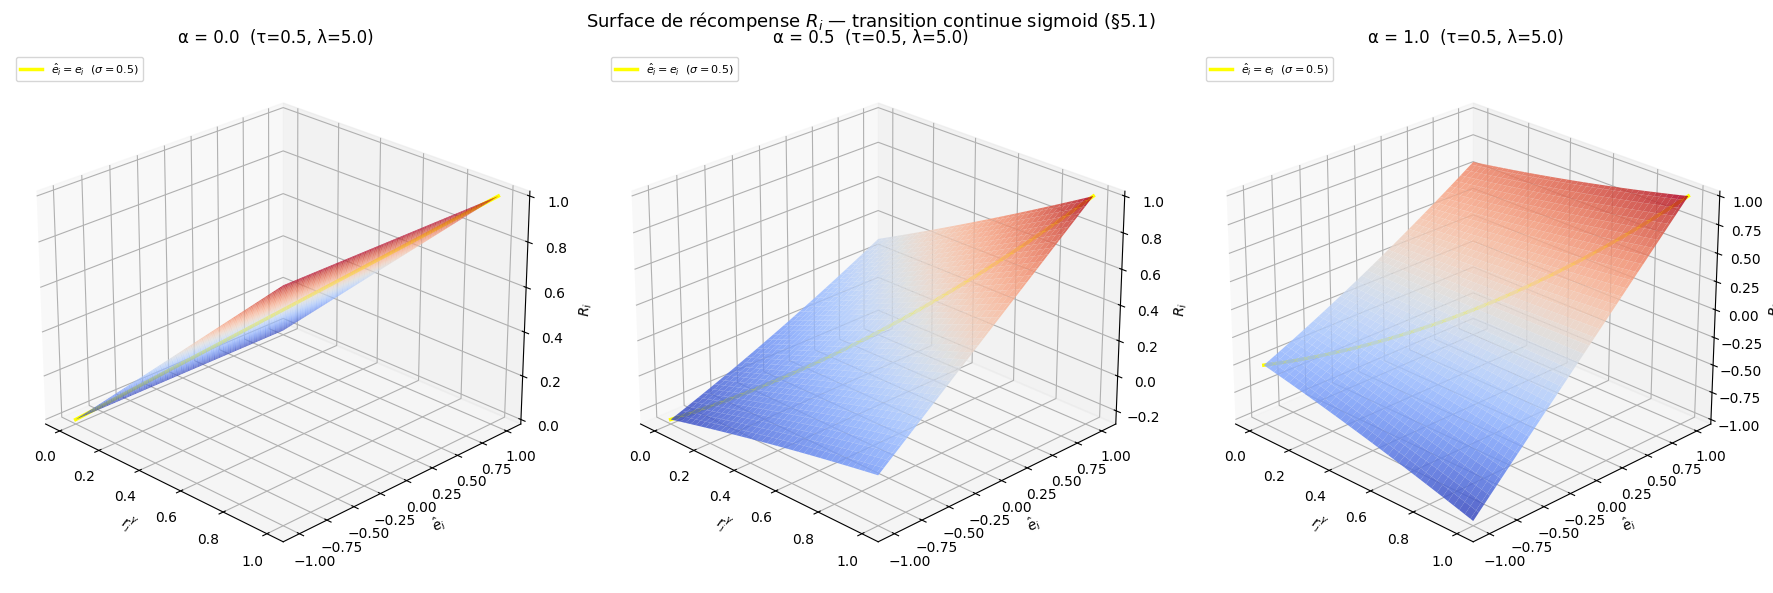

In [7]:
tau = 0.5
lam = 5.0  # sharpness λ : plus grand = plus proche du seuil dur
r_i_vals = np.linspace(0, 1, 80)
e_hat_vals = np.linspace(-1, 1, 80)
R_i_grid, E_hat_grid = np.meshgrid(r_i_vals, e_hat_vals)

# Frontière conceptuelle ê_i = e_i (où σ = 0.5)
e_i_boundary = phi(r_i_vals, tau)

alphas_to_test = [0.0, 0.5, 1.0]
fig = plt.figure(figsize=(18, 6))

for idx, alpha in enumerate(alphas_to_test):
    Z = compute_reward(R_i_grid, E_hat_grid, alpha, tau, lam)

    ax = fig.add_subplot(1, 3, idx + 1, projection='3d')
    surf = ax.plot_surface(R_i_grid, E_hat_grid, Z, cmap='coolwarm', edgecolor='none', alpha=0.85)

    # Tracer la frontière ê_i = e_i (σ = 0.5, transition à mi-chemin)
    z_boundary = compute_reward(r_i_vals, e_i_boundary, alpha, tau, lam)
    ax.plot(r_i_vals, e_i_boundary, z_boundary, color='yellow', linewidth=2.5,
            label=r'$\hat{e}_i = e_i$  ($\sigma=0.5$)')

    ax.set_xlabel(r'$r_i^\gamma$')
    ax.set_ylabel(r'$\hat{e}_i$')
    ax.set_zlabel(r'$R_i$')
    ax.set_title(f'α = {alpha}  (τ={tau}, λ={lam})')
    ax.legend(loc='upper left', fontsize=8)
    ax.view_init(elev=25, azim=-45)

plt.suptitle(r"Surface de récompense $R_i$ — transition continue sigmoid (§5.1)", fontsize=13)
plt.tight_layout()
plt.show()

In [8]:
# Vérification des cas limites — §5.4
print("=== Cas limites §5.4 ===\n")
cases = [
    ("Tous mangent       (r_i=1, ê_i=1, e_i=1)",    1.0,  1.0),
    ("Tous crèvent égal  (r_i=0, ê_i=-1, e_i=-1)",  0.0, -1.0),
    ("Je mange, tous crèvent (r_i=1, ê_i=-1, e_i=1)", 1.0, -1.0),
]
for label, r_i, e_hat in cases:
    for alpha in [0.0, 0.5, 1.0]:
        R = compute_reward(np.array([r_i]), np.array([e_hat]), alpha)[0]
        e_i_val = phi(np.array([r_i]))[0]
        cond = "scalé" if e_hat < e_i_val else "non scalé"
        print(f"  {label}  α={alpha:.1f}  [{cond:9s}]  R_i = {R:+.3f}")
    print()

=== Cas limites §5.4 ===

  Tous mangent       (r_i=1, ê_i=1, e_i=1)  α=0.0  [non scalé]  R_i = +1.000
  Tous mangent       (r_i=1, ê_i=1, e_i=1)  α=0.5  [non scalé]  R_i = +1.000
  Tous mangent       (r_i=1, ê_i=1, e_i=1)  α=1.0  [non scalé]  R_i = +1.000

  Tous crèvent égal  (r_i=0, ê_i=-1, e_i=-1)  α=0.0  [non scalé]  R_i = +0.000
  Tous crèvent égal  (r_i=0, ê_i=-1, e_i=-1)  α=0.5  [non scalé]  R_i = -0.250
  Tous crèvent égal  (r_i=0, ê_i=-1, e_i=-1)  α=1.0  [non scalé]  R_i = -0.500

  Je mange, tous crèvent (r_i=1, ê_i=-1, e_i=1)  α=0.0  [scalé    ]  R_i = +1.000
  Je mange, tous crèvent (r_i=1, ê_i=-1, e_i=1)  α=0.5  [scalé    ]  R_i = +0.000
  Je mange, tous crèvent (r_i=1, ê_i=-1, e_i=1)  α=1.0  [scalé    ]  R_i = -1.000

